In [1]:
# BƯỚC 1: KHAI BÁO CÁC THƯ VIỆN CẦN THIẾT
print("Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64")

from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np
import os
import urllib.request
%matplotlib inline

print("Đã khai báo các thư viện thành công.")

Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64
Đã khai báo các thư viện thành công.


Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64


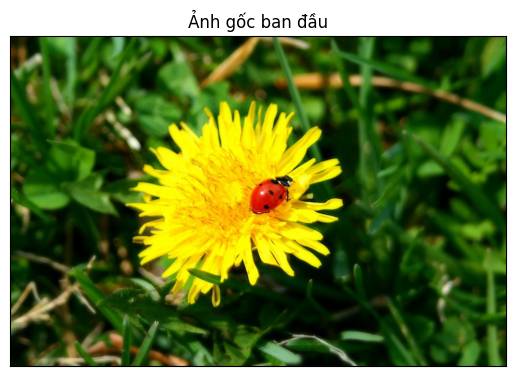

In [2]:
# BƯỚC 2: ĐỌC VÀ HIỂN THỊ FILE ẢNH
print("Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64")

# Tự động tải ảnh mẫu nếu trong thư mục chưa có file dog.png
if not os.path.exists('dog.png'):
    url = "https://raw.githubusercontent.com/ageron/handson-ml2/master/images/unsupervised_learning/ladybug.png"
    urllib.request.urlretrieve(url, 'dog.png')

# Đọc file ảnh
image = Image.open('dog.png')

# Hiển thị ảnh
axes = plt.axes(xticks=[], yticks=[])
axes.imshow(image)
plt.title("Ảnh gốc ban đầu")
plt.show()

In [3]:
# BƯỚC 3: TIỀN XỬ LÝ MẢNG ẢNH
print("Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64")

# Chuyển ảnh thành mảng số và lấy chiều cao, rộng
imarr = np.array(image)
rows = imarr.shape[0]
cols = imarr.shape[1]

print(f"Kích thước ảnh gốc: {rows} dòng (cao) x {cols} cột (rộng) x {imarr.shape[2]} kênh màu")

# Biến đổi giá trị màu về đoạn [0, 1] và chuyển ma trận 3 chiều thành 2 chiều (rows * cols, 3)
data = imarr / 255.0
data = data.reshape(rows * cols, 3)

print("Kích thước dữ liệu mảng sau khi reshape:", data.shape)

Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64
Kích thước ảnh gốc: 533 dòng (cao) x 800 cột (rộng) x 3 kênh màu
Kích thước dữ liệu mảng sau khi reshape: (426400, 3)


In [4]:
# BƯỚC 4: GOM CỤM K-MEANS GIẢM CÒN 32 MÀU
print("Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64")

# Chạy K-Means với số cụm mong muốn là 32
print("Đang tiến hành gom cụm K-Means với k = 32 màu...")
kmeans = KMeans(n_clusters=32, max_iter=300, random_state=42)
kmeans.fit(data)

# Thay thế từng pixel bằng màu của tâm cụm tương ứng
new_colors = kmeans.cluster_centers_[kmeans.predict(data)]
print("Đã hoàn tất gom cụm và gán màu mới cho từng điểm ảnh.")

Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64
Đang tiến hành gom cụm K-Means với k = 32 màu...
Đã hoàn tất gom cụm và gán màu mới cho từng điểm ảnh.


Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64


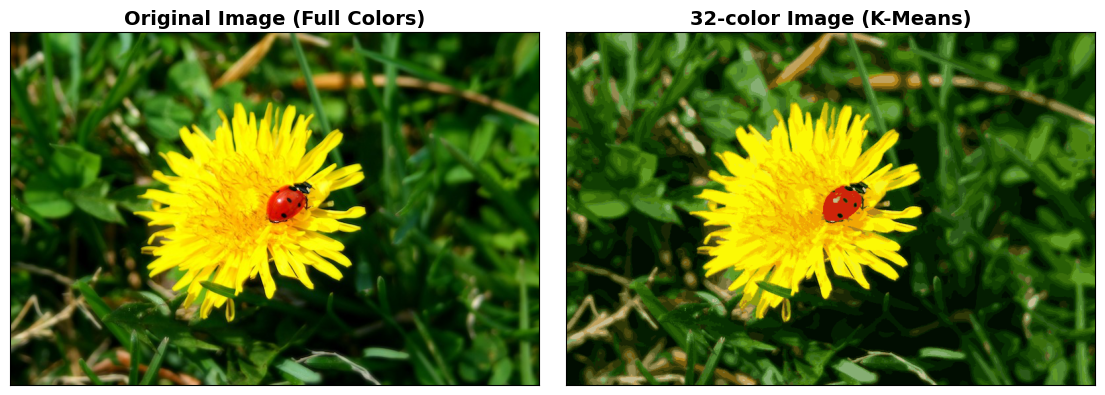

In [5]:
# BƯỚC 5: KHÔI PHỤC VÀ SO SÁNH ẢNH GỐC VỚI ẢNH 32 MÀU
print("Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64")

# Khôi phục mảng từ 2 chiều thành 3 chiều như ban đầu
img_recolored = new_colors.reshape(imarr.shape)

# Biểu diễn hình kết quả và so sánh với ảnh gốc
fig, ax = plt.subplots(1, 2, figsize=(14, 6), subplot_kw=dict(xticks=[], yticks=[]))
fig.subplots_adjust(wspace=0.05)

ax[0].imshow(image)
ax[0].set_title('Original Image (Full Colors)', size=14, fontweight='bold')

ax[1].imshow(img_recolored)
ax[1].set_title('32-color Image (K-Means)', size=14, fontweight='bold')

plt.show()

In [6]:
# BƯỚC 6: LƯU HÌNH XUỐNG ĐĨA CỨNG VÀ SO SÁNH DUNG LƯỢNG FILE
print("Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64")

# Đưa giá trị màu từ [0, 1] về lại thang chuẩn [0, 255]
img_save = img_recolored * 255
new_img = Image.fromarray(img_save.astype(np.uint8))

# Lưu ảnh kết quả xuống file
new_img.save('compressed_img2.png')

# So sánh dung lượng file
orig_size = os.path.getsize('dog.png')
comp_size = os.path.getsize('compressed_img2.png')

print(f"Dung lượng ảnh gốc:              {orig_size:,} bytes")
print(f"Dung lượng ảnh sau khi nén:      {comp_size:,} bytes")
print(f"=> Dung lượng giảm được:         {(1 - comp_size / orig_size) * 100:.2f}%")
print("=> Đã lưu thành công file: compressed_img2.png")

Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64
Dung lượng ảnh gốc:              574,025 bytes
Dung lượng ảnh sau khi nén:      162,963 bytes
=> Dung lượng giảm được:         71.61%
=> Đã lưu thành công file: compressed_img2.png
